In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

TABLES_DIR = PROJECT_ROOT / "tables"

comparison = pd.read_csv(
    TABLES_DIR / "all_models_validation_comparison.csv"
)

display(comparison.sort_values("RMSE"))

,Model,RMSE,MAE,Safe_MAPE
0,"GARCH(1,1)",0.034771,0.019197,29.495222
1,Linear Regression,0.035895,0.018616,27.730350
2,XGBoost,0.037992,0.019562,27.495317
3,Random Forest,0.038677,0.019927,27.855195
4,Persistence,0.043013,0.023945,37.751981
5,LSTM,0.049478,0.023611,32.598020


In [2]:
lstm = comparison.loc[
    comparison["Model"] == "LSTM"
].iloc[0]

persistence = comparison.loc[
    comparison["Model"] == "Persistence"
].iloc[0]

rmse_improvement = (
    (persistence["RMSE"] - lstm["RMSE"])
    / persistence["RMSE"]
) * 100

mae_improvement = (
    (persistence["MAE"] - lstm["MAE"])
    / persistence["MAE"]
) * 100

print(f"LSTM RMSE improvement: {rmse_improvement:.2f}%")
print(f"LSTM MAE improvement: {mae_improvement:.2f}%")

LSTM RMSE improvement: -15.03%
LSTM MAE improvement: 1.39%


In [3]:
lstm_predictions = pd.read_csv(
    TABLES_DIR / "lstm_validation_predictions.csv",
    parse_dates=["Date"]
)

lstm_predictions["Error"] = (
    lstm_predictions["Actual"]
    - lstm_predictions["Predicted"]
)

lstm_predictions["Absolute_Error"] = (
    lstm_predictions["Error"].abs()
)

largest_errors = (
    lstm_predictions
    .sort_values("Absolute_Error", ascending=False)
    .head(15)
)

display(largest_errors)

,Date,Actual,Predicted,Error,Absolute_Error
107,2020-06-05,0.082257,0.405252,-0.322995,0.322995
110,2020-06-10,0.082125,0.386180,-0.304055,0.304055
106,2020-06-04,0.084779,0.377097,-0.292319,0.292319
109,2020-06-09,0.082102,0.372875,-0.290772,0.290772
108,2020-06-08,0.082105,0.371999,-0.289894,0.289894
105,2020-06-03,0.084725,0.347049,-0.262324,0.262324
34,2020-02-21,0.252435,0.028017,0.224417,0.224417
32,2020-02-19,0.248722,0.025752,0.222970,0.222970
33,2020-02-20,0.248737,0.025928,0.222809,0.222809
31,2020-02-18,0.243006,0.025721,0.217285,0.217285


In [4]:
print("Actual volatility:")
print(lstm_predictions["Actual"].describe())

print("\nPredicted volatility:")
print(lstm_predictions["Predicted"].describe())

print("\nCorrelation between actual and predicted:")
print(
    lstm_predictions[
        ["Actual", "Predicted"]
    ].corr()
)

Actual volatility:
count    756.000000
mean       0.059637
std        0.040650
min        0.019382
25%        0.036552
50%        0.052686
75%        0.070040
max        0.270908
Name: Actual, dtype: float64

Predicted volatility:
count    756.000000
mean       0.049574
std        0.037418
min        0.025457
25%        0.029689
50%        0.047843
75%        0.055502
max        0.405252
Name: Predicted, dtype: float64

Correlation between actual and predicted:
            Actual  Predicted
Actual     1.00000    0.23095
Predicted  0.23095    1.00000


In [5]:
print("=" * 60)
print("LSTM VOLATILITY DISTRIBUTION")
print("=" * 60)

summary = pd.DataFrame({
    "Actual": lstm_predictions["Actual"].describe(),
    "Predicted": lstm_predictions["Predicted"].describe()
})

display(summary.round(6))

print("\nCorrelation:")
print(
    lstm_predictions[
        ["Actual", "Predicted"]
    ].corr().round(4)
)

LSTM VOLATILITY DISTRIBUTION


,Actual,Predicted
count,756.000000,756.000000
mean,0.059637,0.049574
std,0.040650,0.037418
min,0.019382,0.025457
25%,0.036552,0.029689
50%,0.052686,0.047843
75%,0.070040,0.055502
max,0.270908,0.405252



Correlation:
           Actual  Predicted
Actual      1.000      0.231
Predicted   0.231      1.000


In [6]:
lstm_predictions["Squared_Error"] = (
    lstm_predictions["Error"] ** 2
)

largest_squared_errors = (
    lstm_predictions
    .sort_values("Squared_Error", ascending=False)
    .head(15)
)

total_squared_error = (
    lstm_predictions["Squared_Error"].sum()
)

top_15_squared_error = (
    largest_squared_errors["Squared_Error"].sum()
)

contribution = (
    top_15_squared_error / total_squared_error
) * 100

print(
    f"Top 15 observations contribute "
    f"{contribution:.2f}% of total squared error."
)

display(
    largest_squared_errors[
        [
            "Date",
            "Actual",
            "Predicted",
            "Squared_Error"
        ]
    ]
)

Top 15 observations contribute 51.18% of total squared error.


,Date,Actual,Predicted,Squared_Error
107,2020-06-05,0.082257,0.405252,0.104326
110,2020-06-10,0.082125,0.386180,0.092450
106,2020-06-04,0.084779,0.377097,0.085450
109,2020-06-09,0.082102,0.372875,0.084549
108,2020-06-08,0.082105,0.371999,0.084038
105,2020-06-03,0.084725,0.347049,0.068814
34,2020-02-21,0.252435,0.028017,0.050363
32,2020-02-19,0.248722,0.025752,0.049716
33,2020-02-20,0.248737,0.025928,0.049644
31,2020-02-18,0.243006,0.025721,0.047213


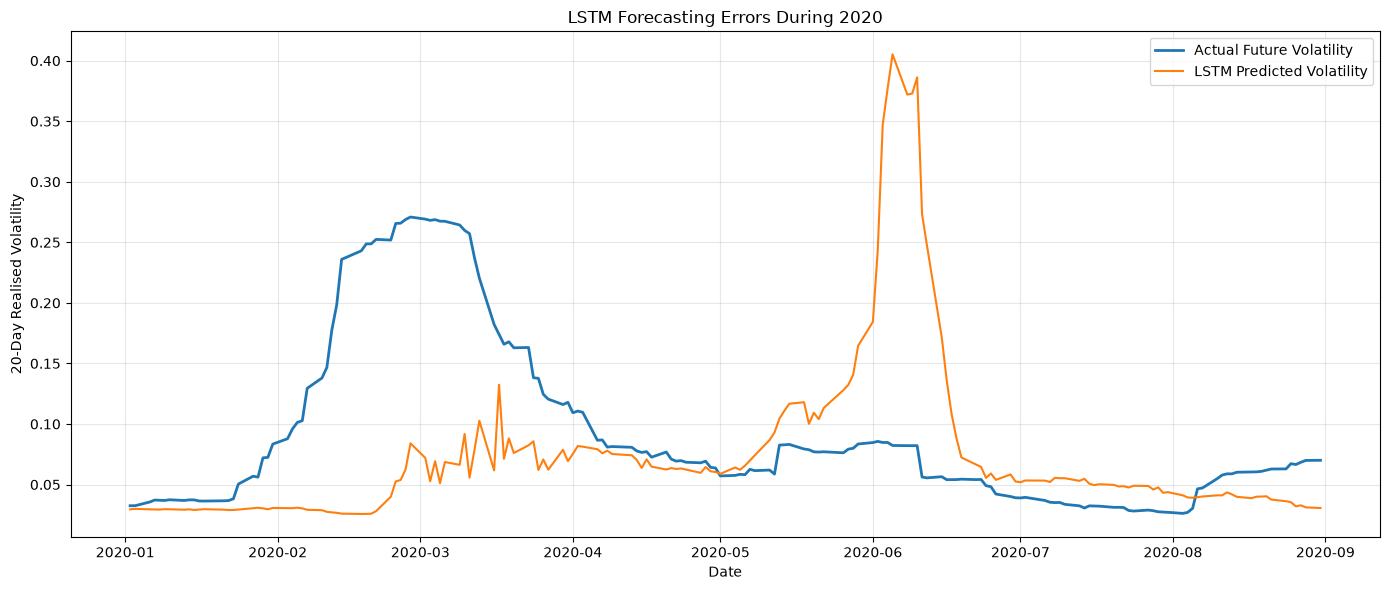

In [7]:
import matplotlib.pyplot as plt

period = lstm_predictions[
    (lstm_predictions["Date"] >= "2020-01-01") &
    (lstm_predictions["Date"] <= "2020-08-31")
].copy()

plt.figure(figsize=(14, 6))

plt.plot(
    period["Date"],
    period["Actual"],
    label="Actual Future Volatility",
    linewidth=2
)

plt.plot(
    period["Date"],
    period["Predicted"],
    label="LSTM Predicted Volatility",
    linewidth=1.5
)

plt.title(
    "LSTM Forecasting Errors During 2020"
)

plt.xlabel("Date")
plt.ylabel("20-Day Realised Volatility")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()